# Rolulabo. Proyecto integrador de Aprendizaje de Máquina

**Universidad Panamericana, Facultad de Ingeniería. COM194 Aprendizaje de Máquina.**
**Equipo.** Gabriel Álvarez Mendoza (0261445), Eduardo Gutiérrez, Emiliano Luna y Rodrigo Naranjo Hernández (0250016).

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gabrielalvarezsurexs/rolulabo/blob/main/notebooks/rolulabo_analisis.ipynb)

Notebook de evidencia. Contiene el procesamiento de datos, la implementación, la evaluación y la comparación de modelos, organizado con los puntos A a E de la rúbrica. La lógica vive en los módulos de `src/` para que el dashboard, las pruebas y los documentos usen exactamente el mismo código. Aquí se ejecuta paso a paso y se muestra la implementación de las partes clave.

**Cómo ejecutarlo.** En Google Colab, Entorno de ejecución, Ejecutar todo. La primera celda clona el repositorio e instala la versión de scikit-learn fijada en `uv.lock`. Si Colab pide reiniciar el entorno, se reinicia y se vuelve a ejecutar todo. En una computadora, `uv sync` y luego `uv run jupyter lab`.

## Configuración

In [1]:
# Prepara el entorno. En Colab clona el repositorio e instala las versiones de
# scikit-learn y scipy fijadas en uv.lock, que son las que determinan los
# números. Fuera de Colab usa la carpeta local del proyecto.
import os, subprocess, sys
from pathlib import Path

REPO = "https://github.com/gabrielalvarezsurexs/rolulabo"
EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    ROOT = Path("/content/rolulabo")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1", REPO, str(ROOT)], check=True)
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

import tomllib
from importlib.metadata import version
from packaging.markers import Marker

def version_fijada(nombre):
    lock = tomllib.loads((ROOT / "uv.lock").read_text(encoding="utf-8"))
    for p in lock["package"]:
        if p["name"] == nombre and (not p.get("resolution-markers") or any(Marker(m).evaluate() for m in p["resolution-markers"])):
            return p["version"]

fijas = {n: version_fijada(n) for n in ["scikit-learn", "scipy"]}
faltan = {n: v for n, v in fijas.items() if version(n) != v}
if faltan and EN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + [f"{n}=={v}" for n, v in faltan.items()], check=True)
    if any(m in sys.modules for m in ("sklearn", "scipy")):
        print("Se instalaron las versiones fijas. Reinicia el entorno y vuelve a ejecutar todo.")
        os.kill(os.getpid(), 9)
elif faltan:
    print("Aviso. Versiones distintas a uv.lock, los números pueden variar:", faltan, "Usa uv sync y uv run jupyter lab.")

os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
print("Entorno listo, en Colab:", EN_COLAB, "| versiones", {n: version(n) for n in fijas})

Entorno listo, en Colab: False | versiones {'scikit-learn': '1.9.1', 'scipy': '1.18.1'}


In [2]:
import json
import inspect
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 120)

import config, etl, loss_model, delivery, segmentation, cross, hypotheses, decision_rules
# viz.py fija el backend Agg para guardar figuras. En el notebook se regresa al inline.
get_ipython().run_line_magic("matplotlib", "inline")
fig = lambda name: display(Image(str(ROOT / "reports" / "figures" / f"{name}.png")))

## A. Planteamiento del problema

**Problema.** Rolulabo, una cadena ficticia de artículos de oficina, muebles y tecnología en Estados Unidos, vende más cada año pero casi una de cada cinco líneas de venta cierra con pérdida. Las pérdidas se detectan hasta el cierre contable, los pedidos incumplen la promesa de entrega y la empresa trata igual a todos sus clientes.

**Importancia y beneficiarios.** El crecimiento en ventas no se traduce en margen. La solución beneficia a Comercial y Finanzas, que deciden los descuentos, a Operaciones, que define la promesa de entrega, a Marketing, que asigna presupuesto por cliente, y a Dirección, que aprueba la política.

**Preguntas analíticas.**
1. Con la información disponible al capturar un pedido, se puede anticipar si una línea cerrará con pérdida, y hasta qué descuento conviene cada subcategoría? Clasificación.
2. Se puede anticipar qué pedidos llegarán tarde? Clasificación.
3. Existen grupos de clientes con rentabilidad distinta? Agrupamiento.

**Objetivo medible.** En los estados tratados, bajar las líneas con pérdida a menos de 5% y subir el margen neto a más de 20%, sin que los pedidos por cliente caigan más de 10% contra un grupo de control. En entregas, cumplir la promesa en más de 95% de los pedidos. La línea base se calcula abajo.

**ODS.** El proyecto se relaciona con el ODS 8, Trabajo decente y crecimiento económico, meta 8.2, que busca elevar la productividad económica mediante la modernización tecnológica y la innovación. La relación es indirecta y a nivel empresa. El análisis eleva la utilidad por transacción con datos que la empresa ya tiene. No se vincula con ODS ambientales porque los datos no traen consumo de recursos ni residuos.

## B. Obtención y preparación de datos

**Fuente.** Sample Superstore, versión completa con descuento, cantidad y utilidad, publicada en Kaggle por Vivek Chowdhury. https://www.kaggle.com/datasets/vivek468/superstore-dataset-final. El archivo original está en `data/raw/superstore.csv` y nunca se modifica. Es un dataset sintético y público, sin información personal real.

El ETL valida esquema, nulos, duplicados, reglas de dominio y consistencia por pedido, deriva variables y construye las tablas procesadas y un modelo estrella para BI.

In [3]:
q = etl.run()
pd.Series({k: v for k, v in q.items() if k not in ("atipicos_y_sesgos", "modelo_estrella")}, dtype=object).to_frame("valor")

,valor
filas_crudas,9994
columnas_esperadas_ok,True
nulos_totales,0
duplicados_exactos_eliminados,1
envio_antes_de_pedido,0
ventas_no_positivas,0
cantidad_no_positiva,0
descuento_fuera_de_rango,0
paises,[United States]
pedidos_inconsistentes,0


In [4]:
lines = config.read_csv(ROOT / "data/processed/lines.csv", parse_dates=["order_date"])
base = lines[lines.year == config.TEST_YEAR]
print(f"Línea base del objetivo. Líneas con pérdida {lines.is_loss.mean():.1%}, margen 2017 {base.profit.sum() / base.sales.sum():.1%}, "
      f"pérdida total {-lines.loc[lines.profit < 0, 'profit'].sum():,.0f} USD")

Línea base del objetivo. Líneas con pérdida 18.7%, margen 2017 12.7%, pérdida total 156,119 USD


### Variables utilizadas y transformaciones

In [5]:
diccionario = pd.DataFrame([
    ["discount", "Descuento aplicado a la línea", "Variable del modelo"],
    ["sub_category, category", "Subcategoría y categoría del producto", "Variable del modelo, one-hot"],
    ["region, segment, ship_mode", "Región, segmento del cliente y modalidad de envío", "Variable del modelo, one-hot"],
    ["quantity, month", "Cantidad y mes del pedido", "Variable del modelo"],
    ["list_price", "Ventas / cantidad / (1 - descuento)", "Variable del modelo en logaritmo"],
    ["unit_cost", "(Ventas - utilidad) / cantidad", "Solo topes y simulación, nunca en el modelo"],
    ["breakeven_discount", "1 - costo / precio de lista", "Solo topes y simulación, nunca en el modelo"],
    ["is_loss", "1 si la utilidad de la línea es negativa", "Objetivo del problema 1"],
    ["days_to_ship, is_late", "Días de envío y si exceden la promesa supuesta", "Objetivo del problema 2"],
    ["recency, frequency, monetary, margin, avg_discount", "Variables por cliente", "Segmentación"],
], columns=["Variable", "Definición", "Uso"])
diccionario

,Variable,Definición,Uso
0,discount,Descuento aplicado a la línea,Variable del modelo
1,"sub_category, category",Subcategoría y categoría del producto,"Variable del modelo, one-hot"
2,"region, segment, ship_mode","Región, segmento del cliente y modalidad de envío","Variable del modelo, one-hot"
3,"quantity, month",Cantidad y mes del pedido,Variable del modelo
4,list_price,Ventas / cantidad / (1 - descuento),Variable del modelo en logaritmo
5,unit_cost,(Ventas - utilidad) / cantidad,"Solo topes y simulación, nunca en el modelo"
6,breakeven_discount,1 - costo / precio de lista,"Solo topes y simulación, nunca en el modelo"
7,is_loss,1 si la utilidad de la línea es negativa,Objetivo del problema 1
8,"days_to_ship, is_late",Días de envío y si exceden la promesa supuesta,Objetivo del problema 2
9,"recency, frequency, monetary, margin, avg_discount",Variables por cliente,Segmentación


In [6]:
lines[["sales", "quantity", "discount", "profit", "list_price", "unit_cost", "breakeven_discount"]].describe().round(3)

,sales,quantity,discount,profit,list_price,unit_cost,breakeven_discount
count,9993.000,9993.000,9993.000,9993.000,9993.000,9993.000,9993.000
mean,229.853,3.790,0.156,28.661,75.559,53.111,0.341
std,623.276,2.225,0.206,234.271,188.967,122.254,0.136
min,0.444,1.000,0.000,-6599.978,0.990,0.544,-0.000
25%,17.280,2.000,0.000,1.731,6.480,3.474,0.260
50%,54.480,3.000,0.200,8.671,19.980,12.934,0.340
75%,209.940,5.000,0.200,29.364,76.980,54.522,0.470
max,22638.480,14.000,0.800,8399.976,7546.160,4074.926,0.500


### Valores faltantes, atípicos y sesgos

Valores faltantes: 0 | duplicados eliminados: 1
Tratamiento de atípicos: No se eliminan. Precio en logaritmo, modelos de árboles y margen recortado en p1 y p99 para la segmentación


,atipicos,atipicos_pct,min,max,mediana
sales,1167.0,0.117,0.444,22638.480,54.480
quantity,170.0,0.017,1.000,14.000,3.000
list_price,1025.0,0.103,0.990,7546.160,19.980
profit,1881.0,0.188,-6599.978,8399.976,8.671


El 1% de las líneas con más venta concentra el 19.6% de las ventas


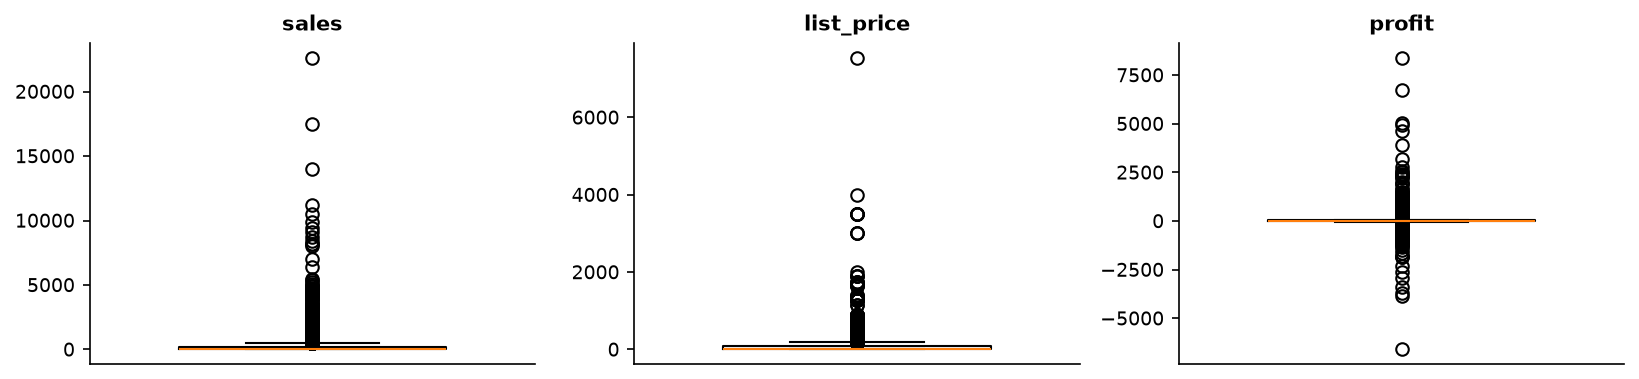

In [7]:
ats = q["atipicos_y_sesgos"]
print("Valores faltantes:", q["nulos_totales"], "| duplicados eliminados:", q["duplicados_exactos_eliminados"])
print("Tratamiento de atípicos:", ats["tratamiento"])
display(pd.DataFrame(ats["atipicos_iqr"]).T.round(3))
print(f"El 1% de las líneas con más venta concentra el {ats['ventas_top_1pct_lineas']:.1%} de las ventas")
fig_, ax = plt.subplots(1, 3, figsize=(11, 2.6))
for a, c in zip(ax, ["sales", "list_price", "profit"]):
    a.boxplot(lines[c], widths=0.6); a.set_title(c); a.set_xticks([])
plt.tight_layout(); display(fig_); plt.close(fig_)

In [8]:
# Representatividad. Sesgos que condicionan la lectura de los resultados.
pd.DataFrame({k: pd.Series(v) for k, v in ats["representatividad"].items()}).round(3)

,region,segmento,anio,categoria
2014,NaN,NaN,0.199,NaN
2015,NaN,NaN,0.210,NaN
2016,NaN,NaN,0.259,NaN
2017,NaN,NaN,0.331,NaN
Central,0.232,NaN,NaN,NaN
Consumer,NaN,0.519,NaN,NaN
Corporate,NaN,0.302,NaN,NaN
East,0.285,NaN,NaN,NaN
Furniture,NaN,NaN,NaN,0.212
Home Office,NaN,0.178,NaN,NaN


**Sesgos.** De representatividad, West tiene el doble de líneas que South y 2017 pesa un tercio de los datos. De confusión, el descuento es fijo por estado y subcategoría, así que no se puede separar el efecto del estado del efecto del descuento. De selección, solo hay ventas cerradas y no cotizaciones perdidas, por lo que la elasticidad al precio no se puede estimar. Y los datos son sintéticos, la utilidad sale de una fórmula con costo fijo por producto.

### Exploración

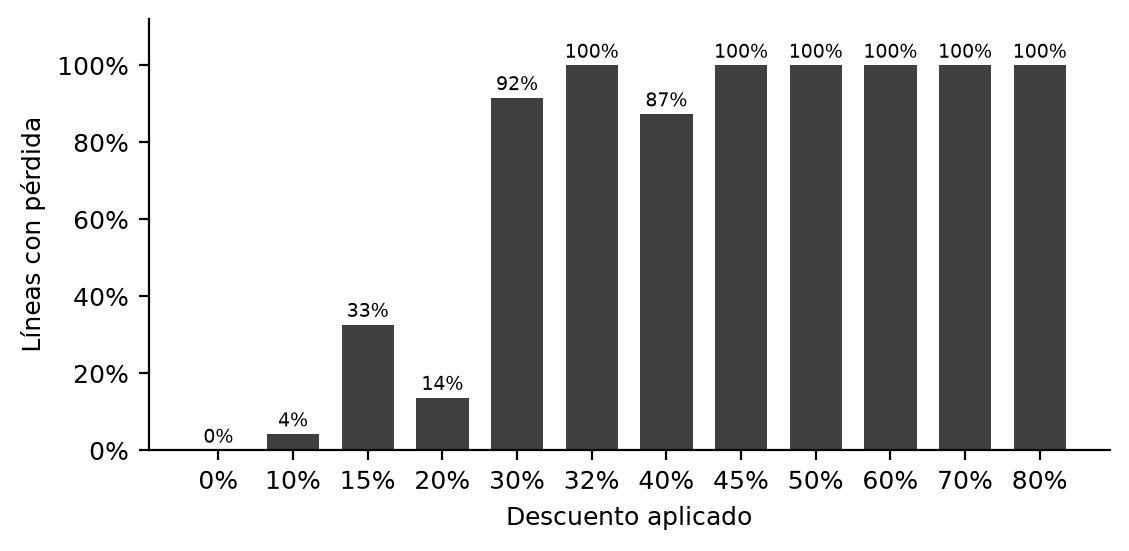

,lineas,ventas,utilidad,perdida_pct,descuento_prom
sub_category,,,,,
Tables,319,206965.532,-17725.481,0.636,0.261
Bookcases,228,114879.996,-3472.556,0.478,0.211
Supplies,190,46673.538,-1189.100,0.174,0.077
Fasteners,217,3024.280,949.518,0.055,0.082
Machines,115,189238.631,3384.757,0.383,0.306
Labels,364,12486.312,5546.254,0.000,0.069
Art,796,27118.792,6527.787,0.000,0.075
Envelopes,254,16476.402,6964.177,0.000,0.080
Furnishings,957,91705.164,13059.144,0.175,0.138


In [9]:
fig("f1_perdida_por_descuento")
lines.groupby("sub_category").agg(lineas=("row_id", "size"), ventas=("sales", "sum"), utilidad=("profit", "sum"),
    perdida_pct=("is_loss", "mean"), descuento_prom=("discount", "mean")).sort_values("utilidad").round(3)

In [10]:
lines.groupby("state").agg(descuento_prom=("discount", "mean"), utilidad=("profit", "sum")).sort_values("descuento_prom", ascending=False).head(12).round(3)

,descuento_prom,utilidad
state,,
Illinois,0.390,-12607.887
Texas,0.370,-25729.356
Pennsylvania,0.329,-15559.960
Ohio,0.325,-16959.318
Colorado,0.316,-6527.858
Arizona,0.304,-3427.925
Florida,0.299,-3399.302
Tennessee,0.291,-5341.694
Oregon,0.289,-1190.470


Dos hallazgos estructurales cambian el planteamiento. El descuento es único por estado y subcategoría, así que es una política y no una decisión del vendedor. Y el costo unitario es constante por producto, así que la pérdida es determinista. Una línea pierde exactamente cuando el descuento supera el descuento de equilibrio.

In [11]:
print("Combinaciones estado y subcategoría con un solo descuento:", q["combinaciones_con_un_solo_descuento"], "de", q["combinaciones_estado_subcategoria"])
print("Exactitud de la regla de equilibrio para explicar la pérdida:", q["regla_equilibrio_exactitud"])

Combinaciones estado y subcategoría con un solo descuento: 656 de 656
Exactitud de la regla de equilibrio para explicar la pérdida: 1.0


## C. Implementación de aprendizaje de máquina

**Tipo de problema.** Problema 1, clasificación binaria con desbalance moderado. Problema 2, clasificación binaria por modalidad de envío. Problema 3, agrupamiento no supervisado.

**Partición y fuga de información.** Entrenamiento con 2014 a 2016 y prueba con 2017, para imitar el uso real sobre pedidos futuros. Dentro de entrenamiento, validación cruzada de ventana creciente para elegir hiperparámetros y umbral. El modelo no usa utilidad, margen, costo ni descuento de equilibrio, porque no se conocen al capturar el pedido o son el propio objetivo.

In [12]:
prohibidas = {"profit", "margin", "unit_cost", "cost_ratio", "breakeven_discount", "is_loss"}
print("Variables del modelo:", loss_model.FEATURES)
assert not prohibidas & set(loss_model.FEATURES), "fuga de información"
print("Sin fuga de información. Entrenamiento", (lines.year < config.TEST_YEAR).sum(), "líneas, prueba", (lines.year == config.TEST_YEAR).sum())

Variables del modelo: ['sub_category', 'category', 'region', 'segment', 'ship_mode', 'discount', 'quantity', 'log_list_price', 'month']
Sin fuga de información. Entrenamiento 6681 líneas, prueba 3312


**Líneas base y modelos.** Tres líneas base. La proporción de la clase, la regla actual del negocio (descuento mayor a 20%) y una regla con el costo histórico de cada producto, que no es aprendizaje de máquina y sirve como referencia honesta. Cuatro modelos de complejidad creciente. Regresión logística, lineal e interpretable. Árbol de decisión, reglas legibles. Random forest y gradient boosting, que capturan la interacción entre descuento y subcategoría que explica la pérdida. La métrica de selección es PR-AUC, adecuada con clases desbalanceadas.

In [13]:
for nombre, (_, escala, rejilla) in loss_model.CANDIDATES.items():
    print(f"{nombre:22s} escalado={escala!s:5s} hiperparámetros={rejilla}")
print("\nImplementación de la validación temporal y la selección:\n")
print(inspect.getsource(loss_model.temporal_folds)); print(inspect.getsource(loss_model.best_threshold)); print(inspect.getsource(loss_model.select_models))

Regresion logistica    escalado=True  hiperparámetros={'C': [0.1, 1.0, 10.0]}
Arbol de decision      escalado=False hiperparámetros={'max_depth': [3, 5, 8, None], 'min_samples_leaf': [1, 10, 30]}
Random forest          escalado=False hiperparámetros={'max_depth': [None, 10], 'min_samples_leaf': [1, 5]}
Gradient boosting      escalado=False hiperparámetros={'learning_rate': [0.05, 0.1], 'max_depth': [None, 6]}

Implementación de la validación temporal y la selección:

def temporal_folds(train: pd.DataFrame):
    """Ventana creciente. 2014 predice 2015, 2014-2015 predicen 2016."""
    years = sorted(train["year"].unique())
    for i in range(1, len(years)):
        tr = train.index[train["year"] < years[i]]
        va = train.index[train["year"] == years[i]]
        yield tr, va

def best_threshold(y, p) -> float:
    """Umbral que maximiza F1 en validacion, buscado en una rejilla de 0.05.

    El F1 es casi plano cerca del optimo. Buscar el maximo exacto sobre la
    curva precision-rec

In [14]:
print(inspect.getsource(loss_model.cost_history_rule))

def cost_history_rule(train: pd.DataFrame, test: pd.DataFrame):
    """Linea base informada que no es aprendizaje de maquina.

    Toma el descuento de equilibrio de cada producto observado en 2014-2016
    (el costo unitario es constante por producto) y marca perdida si el
    descuento de la linea lo supera. Si el producto no tiene historial aplica
    la regla de 20%. Solo usa informacion del pasado, asi que no hay fuga,
    pero supone que el sistema conoce el costo de cada producto.

    Regresa un score continuo (descuento menos equilibrio), la prediccion y
    la mascara de lineas con historial.
    """
    be = train.groupby("product_key")["breakeven_discount"].median()
    be_t = test["product_key"].map(be)
    seen = be_t.notna().values
    margin = np.where(seen, test["discount"].values - be_t.fillna(0).values, test["discount"].values - 0.20)
    return margin, (margin >= 1e-9).astype(int), seen



In [15]:
r1 = loss_model.run()

Seleccion de modelos con validacion temporal


  Regresion logistica: CV PR-AUC 0.943 params {'C': 10.0}


  Arbol de decision: CV PR-AUC 0.938 params {'max_depth': None, 'min_samples_leaf': 30}


  Random forest: CV PR-AUC 0.937 params {'max_depth': 10, 'min_samples_leaf': 1}


  Gradient boosting: CV PR-AUC 0.953 params {'learning_rate': 0.05, 'max_depth': 6}


## D. Evaluación y comparación

Todos los modelos y líneas base se evalúan sobre la misma prueba de 2017 que ninguno vio al entrenar.

In [16]:
tabla = pd.DataFrame(r1["modelos"]).T[["roc_auc", "pr_auc", "f1", "precision", "recall", "perdida_detectada_pct", "umbral"]].astype(float).round(3)
tabla

,roc_auc,pr_auc,f1,precision,recall,perdida_detectada_pct,umbral
Linea base sin modelo,0.500,0.187,0.000,0.000,0.000,NaN,0.50
Regla descuento > 20%,0.940,0.814,0.826,0.976,0.716,0.893,0.20
Regresion logistica,0.985,0.945,0.841,0.846,0.835,0.938,0.75
Arbol de decision,0.986,0.944,0.859,0.919,0.806,0.924,0.85
Random forest,0.988,0.956,0.864,0.814,0.919,0.980,0.50
Gradient boosting,0.991,0.967,0.889,0.905,0.874,0.963,0.45
Regla costo histórico,0.999,0.997,0.995,0.995,0.995,0.999,0.00


Modelo elegido por PR-AUC de validación: Gradient boosting
IC 95% F1 modelo: [0.871, 0.906] | regla actual: [0.802, 0.851] | regla con costo: [0.991, 0.998]
Matriz de confusión: {'tn': 2635, 'fp': 57, 'fn': 78, 'tp': 542}
Descuento exacto de 20%: {'lineas': 1223, 'perdidas': 169, 'regla_detecta': 0, 'modelo_detecta': 94, 'modelo_falsos_positivos': 45}


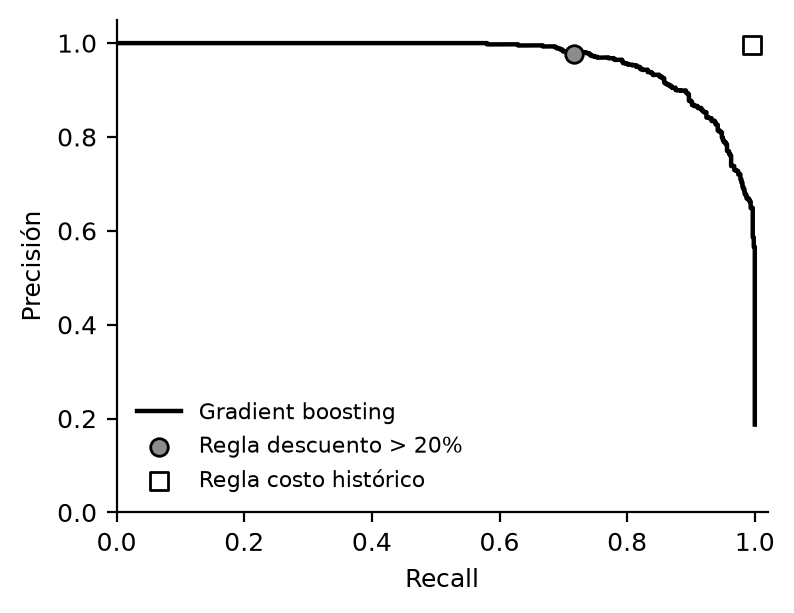

In [17]:
print("Modelo elegido por PR-AUC de validación:", r1["modelo_elegido"])
print("IC 95% F1 modelo:", [round(x, 3) for x in r1["ic95_modelo_elegido"]["f1_ic95"]], "| regla actual:", [round(x, 3) for x in r1["ic95_regla"]["f1_ic95"]],
      "| regla con costo:", [round(x, 3) for x in r1["ic95_regla_costo"]["f1_ic95"]])
print("Matriz de confusión:", r1["matriz_confusion"])
print("Descuento exacto de 20%:", r1["descuento_20"])
fig("f2_precision_recall")

### Interpretación

In [18]:
display(pd.Series(r1["importancia_permutacion"]).round(4).to_frame("caída en PR-AUC"))
print((ROOT / "reports/metrics/arbol_reglas.txt").read_text(encoding="utf-8"))

,caída en PR-AUC
discount,0.7428
sub_category,0.0867
log_list_price,0.0357
category,0.0112
month,0.0017
quantity,0.0015
segment,0.0005
ship_mode,-0.0002
region,-0.0006


|--- num__discount <= 0.250
|   |--- num__discount <= 0.125
|   |   |--- num__discount <= 0.050
|   |   |   |--- class: 0
|   |   |--- num__discount >  0.050
|   |   |   |--- class: 0
|   |--- num__discount >  0.125
|   |   |--- cat__sub_category_Storage <= 0.500
|   |   |   |--- class: 0
|   |   |--- cat__sub_category_Storage >  0.500
|   |   |   |--- class: 1
|--- num__discount >  0.250
|   |--- cat__sub_category_Copiers <= 0.500
|   |   |--- num__discount <= 0.425
|   |   |   |--- class: 1
|   |   |--- num__discount >  0.425
|   |   |   |--- class: 1
|   |--- cat__sub_category_Copiers >  0.500
|   |   |--- class: 0



### Análisis de errores

In [19]:
e = r1["analisis_errores"]
print(f"Falsos negativos {e['falsos_negativos']}, el {e['falsos_negativos_en_20_pct']:.0%} con 20% de descuento, monto {e['falsos_negativos_monto']:,.0f} USD ({e['falsos_negativos_monto_pct']:.1%} del monto perdido)")
print("Por subcategoría:", e["falsos_negativos_por_subcategoria"])
print(f"Falsos positivos {e['falsos_positivos']}, con {e['falsos_positivos_utilidad']:,.0f} USD de utilidad. Por subcategoría:", e["falsos_positivos_por_subcategoria"])

Falsos negativos 78, el 96% con 20% de descuento, monto 1,986 USD (3.7% del monto perdido)
Por subcategoría: {'Accessories': 23, 'Chairs': 13, 'Phones': 13, 'Storage': 9, 'Furnishings': 6}
Falsos positivos 57, con 1,146 USD de utilidad. Por subcategoría: {'Storage': 19, 'Bookcases': 9, 'Phones': 7, 'Accessories': 7, 'Chairs': 6}


### Sensibilidad y robustez

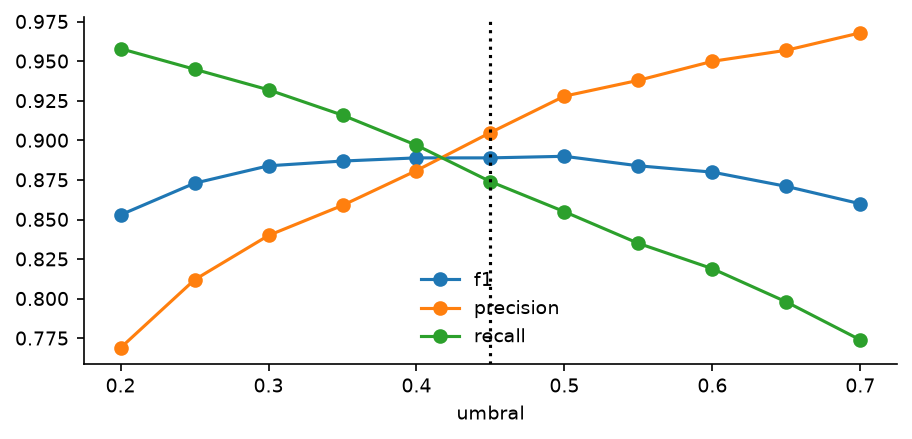

F1 entre 0.884 y 0.890 con el umbral ±0.10


In [20]:
sens = pd.DataFrame(r1["sensibilidad_umbral"]["rejilla"]).round(3)
umbral = r1["modelos"][r1["modelo_elegido"]]["umbral"]
ax = sens.plot(x="umbral", y=["f1", "precision", "recall"], marker="o", figsize=(7, 3)); ax.axvline(umbral, ls=":", c="k")
display(ax.figure); plt.close(ax.figure)
print(f"F1 entre {r1['sensibilidad_umbral']['f1_min_umbral_mas_menos_010']:.3f} y {r1['sensibilidad_umbral']['f1_max_umbral_mas_menos_010']:.3f} con el umbral ±0.10")

### Cuándo no hace falta el modelo

La regla con costo histórico supera a todos los modelos porque la pérdida es determinista. Si el sistema expone el costo de cada producto, esa regla es la mejor herramienta para detectar pérdidas. El modelo aporta donde no hay costo, como segundo método para fijar topes y para confirmar sin costo que la pérdida depende del descuento y la subcategoría.

In [21]:
pd.Series(r1["costo_historico"]).to_frame("valor")

,valor
lineas_con_historial,3205.000000
lineas_con_historial_pct,0.967693
lineas_sin_historial,107.000000
perdidas_sin_historial,11.000000
f1_regla_costo_con_historial,1.000000
f1_modelo_con_historial,0.892977
f1_regla20_con_historial,0.828110
f1_modelo_sin_historial,0.695652
f1_regla20_sin_historial,0.727273


### Topes de descuento y simulación de la política sobre 2017

,sub_category,descuento_prom_actual,descuento_max_actual,perdida_pct_hist,tope_costo,tope_modelo,tope_recomendado
0,Tables,0.259,0.5,0.628,0.10,0.25,0.10
1,Bookcases,0.209,0.7,0.467,0.05,0.25,0.05
2,Supplies,0.079,0.2,0.183,0.00,0.25,0.00
3,Fasteners,0.089,0.2,0.065,0.00,0.25,0.00
4,Labels,0.071,0.2,0.000,0.45,0.30,0.30
5,Art,0.073,0.2,0.000,0.25,0.40,0.25
6,Envelopes,0.078,0.2,0.000,0.45,0.30,0.30
7,Machines,0.309,0.7,0.402,0.25,0.30,0.25
8,Furnishings,0.143,0.6,0.187,0.15,0.25,0.15
9,Appliances,0.161,0.8,0.133,0.25,0.30,0.25


{'lineas_prueba': 3312, 'lineas_afectadas': 925, 'lineas_afectadas_pct': 0.2792874396135266, 'utilidad_actual': 93439.26960000001, 'ventas_actuales': 733215.2552, 'lineas_perdida_actual': 620, 'lineas_perdida_simulada': 49, 'monto_perdida_actual': 53836.1934, 'monto_perdida_simulada': 761.4618000000005, 'utilidad_afectadas_antes': -46057.562600000005, 'utilidad_afectadas_despues': 43162.78869999999, 'perdida_volumen_equilibrio': None}


,perdida_volumen,utilidad,ventas,delta_utilidad
0,0.0,182659.6,822435.6,89220.4
1,0.1,178343.3,791783.2,84904.1
2,0.2,171868.9,745804.6,78429.7
3,0.5,161078.2,669173.5,67639.0
4,1.0,139496.8,515911.4,46057.6


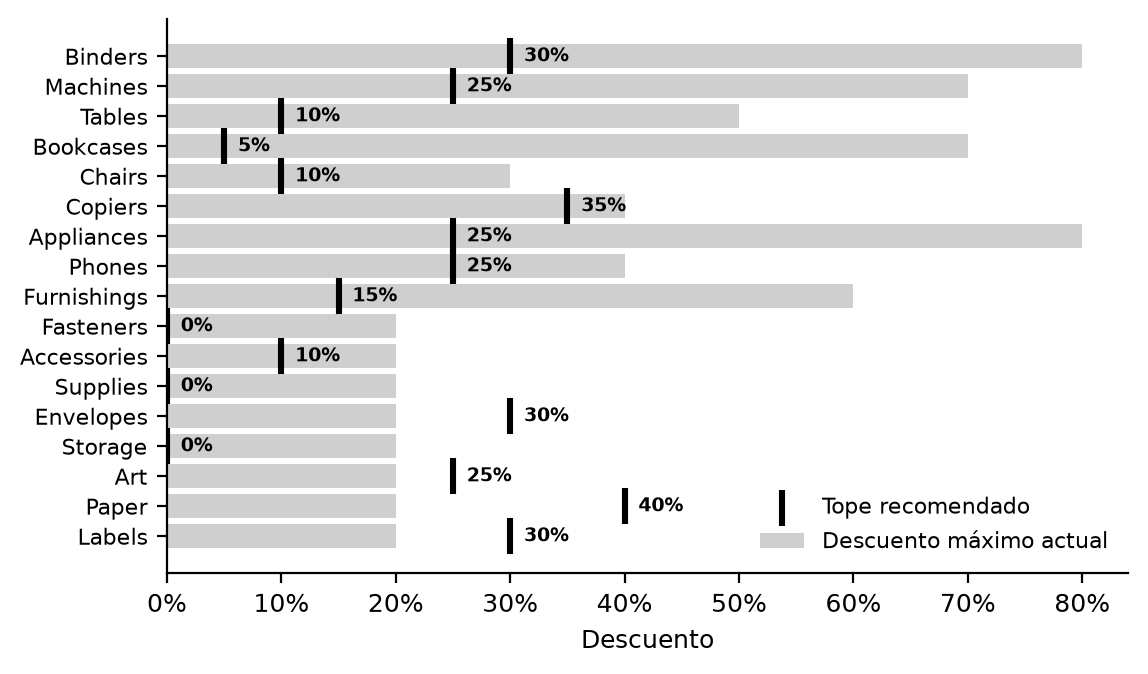

In [22]:
caps = config.read_csv(ROOT / "reports/metrics/topes_descuento.csv")
display(caps[["sub_category", "descuento_prom_actual", "descuento_max_actual", "perdida_pct_hist", "tope_costo", "tope_modelo", "tope_recomendado"]].round(3))
sim = r1["simulacion_2017"]
print({k: v for k, v in sim.items() if k != "escenarios"})
display(pd.DataFrame(sim["escenarios"]).round(1))
fig("f3_topes_descuento")

### Problema 2. Entregas fuera de tiempo

,pedidos,promesa_dias,fuera_de_tiempo_pct,dias_mediana,dias_p90,dias_p95,dias_max
Same Day,264.0,0.0,0.045455,0.0,0.0,0.0,1.0
First Class,787.0,2.0,0.401525,2.0,3.0,3.0,4.0
Second Class,964.0,3.0,0.411826,3.0,5.0,5.0,5.0
Standard Class,2994.0,5.0,0.301937,5.0,7.0,7.0,7.0


Pruebas significativas con Bonferroni: 0 de 24 | alfa 0.0021


,modalidad,variable,chi2,gl,p_valor,v_cramer,significativo_bonferroni
14,Second Class,main_category,15.7248,6,0.0153,0.0904,False
6,First Class,region,12.7677,6,0.0469,0.0901,False
0,Same Day,region,7.9387,3,0.0473,0.1734,False
8,First Class,main_category,5.5774,4,0.2330,0.0596,False
21,Standard Class,month,37.4386,33,0.2726,0.0646,False
23,Standard Class,year,10.0542,9,0.3461,0.0335,False


,modalidad,modelo,auc_prueba,pedidos_prueba,positivos_prueba
0,Same Day,Regresion logistica,0.579,89,5
1,Same Day,Gradient boosting,0.169,89,5
2,First Class,Regresion logistica,0.457,284,119
3,First Class,Gradient boosting,0.492,284,119
4,Second Class,Regresion logistica,0.523,324,133
5,Second Class,Gradient boosting,0.516,324,133
6,Standard Class,Regresion logistica,0.462,990,312
7,Standard Class,Gradient boosting,0.493,990,312
8,Todas (incluye modalidad),Gradient boosting,0.557,1687,569


,modalidad,escenario,promesa_dias,cumplimiento
0,Same Day,actual,0,0.955
1,Same Day,actual + 1,1,1.000
2,Same Day,p95,0,0.955
3,First Class,actual,2,0.598
4,First Class,actual + 1,3,0.999
5,First Class,p95,3,0.999
6,Second Class,actual,3,0.588
7,Second Class,actual + 1,4,0.790
8,Second Class,p95,5,1.000
9,Standard Class,actual,5,0.698


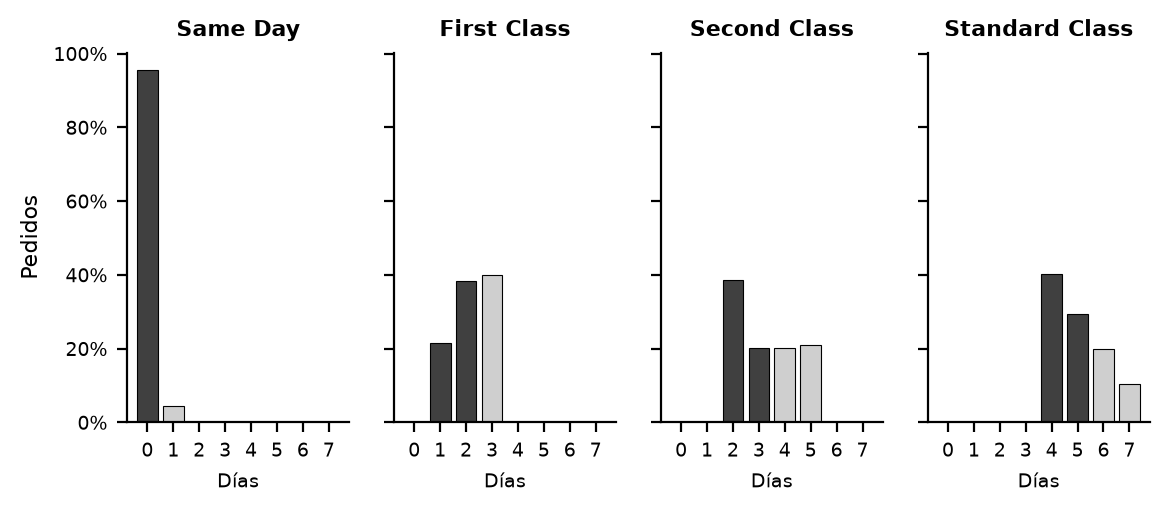

In [23]:
r2 = delivery.run()
display(pd.DataFrame({m: {k: v for k, v in d.items() if k != "distribucion"} for m, d in r2["descripcion"].items() if isinstance(d, dict)}).T)
print("Pruebas significativas con Bonferroni:", r2["pruebas_significativas"], "de", len(r2["pruebas_chi2"]), "| alfa", round(r2["alpha_bonferroni"], 4))
display(pd.DataFrame(r2["pruebas_chi2"]).sort_values("p_valor").head(6).round(4))
display(pd.DataFrame(r2["modelos"]).round(3))
display(pd.DataFrame(r2["sensibilidad_promesa"]).round(3))
fig("f4_dias_envio")

### Problema 3. Segmentación de clientes

,k,inercia,silueta,davies_bouldin
0,2,3020.013,0.312,1.588
1,3,2495.541,0.278,1.386
2,4,2141.219,0.222,1.335
3,5,1910.648,0.210,1.330
4,6,1762.450,0.186,1.392
5,7,1624.719,0.190,1.329
6,8,1521.095,0.180,1.343


k elegido: 4 | silueta 0.222
Estabilidad: {'ari_semillas_media': 0.976, 'ari_semillas_min': 0.939, 'ari_bootstrap_media': 0.715, 'ari_bootstrap_p05': 0.346}


,cluster,clientes,recency,frequency,monetary,profit,margin,avg_discount,loss_line_share,late_rate,ventas_pct,utilidad_pct,perdidas_pct,clientes_pct
nombre,,,,,,,,,,,,,,
Alto valor rentable,0,347,90.617,7.850,4284.785,836.053,0.184,0.124,0.134,0.332,0.647,1.013,0.290,0.438
Cazadores de descuento,1,201,87.567,6.612,2601.031,-226.424,-0.054,0.244,0.336,0.319,0.228,-0.159,0.622,0.253
Inactivos,2,73,595.397,3.342,1362.290,45.700,-0.002,0.216,0.267,0.279,0.043,0.012,0.067,0.092
Compradores ocasionales,3,172,143.593,4.140,1092.121,223.686,0.210,0.100,0.089,0.324,0.082,0.134,0.022,0.217


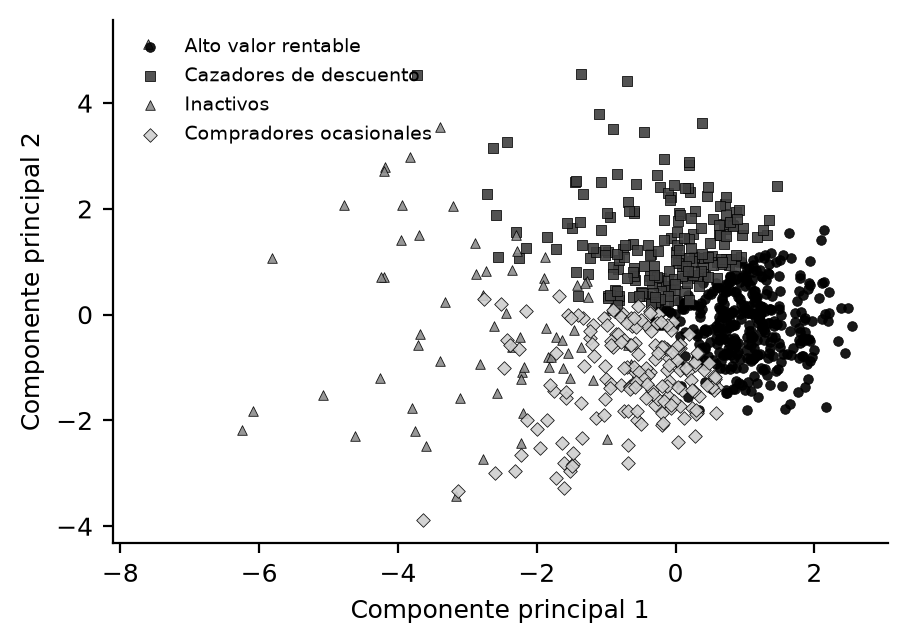

In [24]:
r3 = segmentation.run()
display(pd.DataFrame(r3["seleccion_k"]).round(3))
print("k elegido:", r3["k_elegido"], "| silueta", round(r3["silueta_k"], 3))
print("Estabilidad:", {k: round(v, 3) for k, v in r3["estabilidad"].items()})
display(pd.DataFrame(r3["perfiles"]).set_index("nombre").round(3))
fig("f5_clusters_pca")

## E. Conclusiones y aplicación

In [25]:
r4 = cross.run()
print({k: v for k, v in r4.items() if k != "tabla"})
pd.DataFrame(r4["tabla"]).set_index("cluster_name").round(3)

{'estados_alto_descuento': ['Arizona', 'Colorado', 'Florida', 'Illinois', 'North Carolina', 'Ohio', 'Oregon', 'Pennsylvania', 'Tennessee', 'Texas'], 'lineas_en_estados_alto_descuento_pct': 0.38797158010607424, 'perdida_en_estados_alto_descuento_pct': 0.9326760181388011, 'diferencia_retraso_entre_grupos_pp': 0.06394285164054786, 'chi2_retraso_vs_grupo_p': 0.1856476330438292}


,lineas,ventas,utilidad,perdidas,lineas_perdida_pct,descuento_prom,compras_en_estados_alto_descuento_pct,fuera_de_tiempo_pct,ventas_pct,utilidad_pct,perdidas_pct
cluster_name,,,,,,,,,,,
Alto valor rentable,5569,1486820.227,290110.359,45277.761,0.139,0.127,0.312,0.334,0.647,1.013,0.290
Cazadores de descuento,2564,522807.293,-45511.284,97049.508,0.329,0.241,0.600,0.317,0.228,-0.159,0.622
Compradores ocasionales,1356,187844.776,38473.925,3361.514,0.088,0.098,0.244,0.324,0.082,0.134,0.022
Inactivos,504,99447.193,3336.080,10430.444,0.262,0.206,0.540,0.270,0.043,0.012,0.067


### Hipótesis del negocio, con criterio fijado antes de ver el resultado

In [26]:
r5 = hypotheses.run()
pd.DataFrame(r5["hipotesis"])[["id", "creencia", "criterio", "evidencia", "resultado"]]

,id,creencia,criterio,evidencia,resultado
0,H1,El descuento lo decide cada vendedor en cada venta,Se refuta si al menos 95% de las combinaciones tiene un solo descuento,656 de 656 combinaciones tienen un solo descuento,Refutada
1,H2,Dar más descuento hace que el cliente compre más unidades,Se refuta si la correlación no es significativa (alfa 0.05) o es menor a 0.10 en valor absoluto,"rho = -0.001 (p = 0.94), Kruskal-Wallis p = 0.53. Cantidad promedio de 3.6 a 4.1 unidades en todos los niveles",Refutada
2,H3,"Las pérdidas vienen de cierto tipo de cliente (Consumer, Corporate, Home Office)",Se refuta si la prueba no es significativa (alfa 0.05) o la V de Cramér es menor a 0.10,"Pérdida de 17.5% a 19.3% por segmento, p = 0.19, V = 0.02. Por región va de 10% a 32% (V = 0.21)",Refutada
3,H4,Las pérdidas se concentran en el cuarto trimestre por promociones de temporada,Se refuta si la prueba no es significativa (alfa 0.05),"Pérdida de 17.5% a 19.3% por trimestre, p = 0.29",Refutada
4,H5,"Los retrasos se concentran en ciertas regiones, categorías o meses",Se refuta si ninguna prueba es significativa con Bonferroni y ningún modelo llega a AUC 0.65 en 2017,"0 de 24 pruebas significativas, AUC de 0.46 a 0.52",Refutada
5,H6,Los clientes que dejaron de comprar se fueron por entregas tardías,Se refuta si la prueba de una cola no es significativa (alfa 0.05),"Inactivos 28% de pedidos tarde contra 33% de los activos, en sentido contrario a la creencia (p = 0.98)",Refutada
6,H7,Los clientes que más compran son los más rentables,"Se refuta si la correlación no es positiva, significativa (alfa 0.05) y de al menos 0.10",Ventas contra margen rho = 0.04 (p = 0.29). Descuento contra margen rho = -0.59 (p < 0.001),Refutada
7,H8,Un modelo de aprendizaje de máquina detecta pérdidas mejor que una regla de negocio simple,Se confirma si el intervalo de F1 del modelo queda completo por encima del de la regla actual,"F1 0.889 contra 0.826, intervalos sin traslape. Detecta 94 de 169 pérdidas con 20% de descuento que la regla no ve",Confirmada


### Decisión y score, regla y decisión humana

In [27]:
dec = json.loads((ROOT / "reports/metrics/decision.json").read_text(encoding="utf-8"))
display(pd.DataFrame(dec["opciones"]))
r6 = decision_rules.run()
print(f"Umbral del semáforo {r6['umbral_score']}. Revisión humana en {r6['decisiones_humanas_pct']:.0%} de las líneas, "
      f"unas {r6['decisiones_humanas_por_mes']:.0f} al mes, que cubren el {r6['perdida_cubierta_por_revision_pct']:.1%} del monto perdido")
pd.DataFrame(r6["semaforo_2017"]).round(3)

,opcion,utilidad_2017,riesgo
0,A. Mantener la política actual,93439.2696,Sigue perdiendo dinero en 10 estados
1,B. Topes en todo el país de inmediato,182659.6209,No mide el efecto real en volumen antes de escalar
2,"C. Topes en los 10 estados en dos olas, el resto después",174879.9474,Bajo. La primera ola sirve de experimento contra la segunda


Umbral del semáforo 0.45. Revisión humana en 28% de las líneas, unas 77 al mes, que cubren el 99.3% del monto perdido


,semaforo,lineas,lineas_pct,lineas_por_mes,lineas_con_perdida,tasa_perdida,monto_perdida,monto_perdida_pct
0,Rojo,925,0.279,77.083,602,0.651,53411.107,0.992
1,Amarillo,4,0.001,0.333,3,0.750,50.322,0.001
2,Verde,2383,0.720,198.583,15,0.006,374.764,0.007


In [28]:
# Cumplimiento del objetivo en la simulación de 2017.
s0 = sim["escenarios"][0]
p95 = min(x["cumplimiento"] for x in r2["sensibilidad_promesa"] if x["escenario"] == "p95")
display(Markdown(
    f"- Líneas con pérdida en 2017, de {sim['lineas_perdida_actual']} a {sim['lineas_perdida_simulada']} "
    f"({sim['lineas_perdida_simulada'] / sim['lineas_prueba']:.1%}), meta menos de 5%.\n"
    f"- Margen 2017, de {sim['utilidad_actual'] / sim['ventas_actuales']:.1%} a {s0['utilidad'] / s0['ventas']:.1%} con volumen constante, meta más de 20%.\n"
    f"- Cumplimiento de la promesa al percentil 95, al menos {p95:.1%} en cada modalidad, meta más de 95%.\n"
    f"- Opción C, {dec['opciones'][2]['utilidad_2017']:,.0f} USD de utilidad 2017 simulada contra {dec['opciones'][0]['utilidad_2017']:,.0f} USD actuales."))

- Líneas con pérdida en 2017, de 620 a 49 (1.5%), meta menos de 5%.
- Margen 2017, de 12.7% a 22.2% con volumen constante, meta más de 20%.
- Cumplimiento de la promesa al percentil 95, al menos 95.5% en cada modalidad, meta más de 95%.
- Opción C, 174,880 USD de utilidad 2017 simulada contra 93,439 USD actuales.

**Conclusiones.** El objetivo se cumple en simulación sobre 2017 y falta confirmarlo con el piloto, porque el efecto del precio en el volumen no se observa en estos datos. La pérdida es una política de descuentos y no un error del vendedor. El gradient boosting supera a la regla actual del negocio con intervalos que no se traslapan, pero una regla con el costo histórico del producto lo supera a él, así que en operación conviene usar el costo donde exista y el modelo donde no. El retraso no se puede predecir con los datos disponibles y el ajuste es en la promesa. Los cuatro grupos de clientes son útiles para marketing, con separación moderada.

**Decisión propuesta.** Topes de descuento por subcategoría en los 10 estados de descuento alto, en dos olas que funcionan como experimento controlado. Ningún modelo decide solo, una persona con puesto aprueba cada excepción y queda en bitácora. La decisión final es de Dirección General.

**Limitaciones y confiabilidad.** Datos sintéticos con costo fijo, por eso las métricas son altas. El método se traslada a una empresa real, el nivel de desempeño no. No se observa a quien no compró, la promesa de entrega es un supuesto y hay un solo país. Los resultados son reproducibles, la siguiente celda lo verifica. Mejoras posibles, registrar costo, transportista y entrega real, y estimar elasticidad con el piloto.

### Reproducibilidad

In [29]:
ref = json.loads((ROOT / "tests" / "referencia.json").read_text(encoding="utf-8"))
elegido = r1["modelos"][r1["modelo_elegido"]]
check = {"umbral": (elegido["umbral"], ref["umbral"]), "f1": (round(elegido["f1"], 4), ref["f1"]),
         "semáforo": ({x["semaforo"]: x["lineas"] for x in r6["semaforo_2017"]}, ref["semaforo_2017"])}
for k, (obtenido, esperado) in check.items():
    print(f"{k:9s} obtenido {obtenido} | referencia {esperado} | {'coincide' if obtenido == esperado else 'NO COINCIDE'}")

umbral    obtenido 0.45 | referencia 0.45 | coincide
f1        obtenido 0.8893 | referencia 0.8893 | coincide
semáforo  obtenido {'Rojo': 925, 'Amarillo': 4, 'Verde': 2383} | referencia {'Rojo': 925, 'Amarillo': 4, 'Verde': 2383} | coincide


### Declaración de herramientas e inteligencia artificial

Python con pandas, numpy, scikit-learn, scipy y matplotlib, entorno con uv y versiones fijas en `uv.lock`. Se usó Claude, de Anthropic, como asistente para estructurar código, revisar la metodología, auditar el proyecto contra la rúbrica y redactar borradores. El equipo definió el problema, ejecutó y verificó cada resultado. El detalle de herramientas y verificaciones está en `entregables/Declaracion_Herramientas_Rolulabo.pdf`.

---

**Elaborado por Gabriel Álvarez Mendoza, Eduardo Gutiérrez, Emiliano Luna y Rodrigo Naranjo Hernández**